# Stage 6 (part 2b) — Ablations (Prompt 6.4), skeptical review, end of Stage 6

Each ablation changes **one** thing relative to the full tuned model and asks: does the change matter beyond noise? All runs use
the development data only (targets ≤ 2019-12-31): the 5 expanding CV folds for the classical models and the DL split for the deep
model. Uncertainty: paired monthly block bootstrap (calendar months of the target date, 1,000 resamples, 95 % percentile CI) of
the difference variant − full, computed on seed-mean forecasts.

Code: `src/ablation.py` (classical), `src/deep_ablation.py` (deep), tests `tests/test_ablation.py`.

### Step 1 — Setup

**WHAT:** imports, paths, seeds. **Look for:** nothing unusual — same versions as `06_tuning_part2.ipynb`.

In [1]:
import sys, warnings, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import experiment as E, splits as S, metrics as M, tuning as T, ablation as A, deep_ablation as DA, deep_tuning as DT
import reporting as Rep

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
np.random.seed(0); torch.manual_seed(0); torch.set_num_threads(1)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 70, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
print("variants:", list(A.VARIANTS))

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


variants: ['full', 'set_A', 'B_1984', 'B+solar_1984', 'drop_lags', 'drop_rolling', 'drop_spell', 'drop_season', 'drop_tendency', 'drop_derived', 'thr_0.1', 'thr_2.5', 'no_class_weights', 'win_1998', 'win_2000', 'win_2010', 'imerg_1998']


**Interpretation:** 17 classical variants are defined. All of them were verified by `tests/test_ablation.py` (23 tests): no target after
2019-12-31, window restriction applied, references on the full fold, each family drop removes exactly its columns, and IMERG is used for both
features and next-day targets.

**Decision:** proceed with the suite as designed.

**Paper note:** *Each ablation altered a single design factor relative to the tuned reference configuration and was evaluated with the
same chronological folds and metrics.*

### Step 2 — Design of the ablation suite

| # | Ablation | Variant(s) | Compared with | Models |
|---|---|---|---|---|
| 1 | Feature set | `set_A` (71 features); `B+solar_1984` (+ 10 solar-radiation features) | `full` (B); `B_1984` (B trained from 1984, the solar twin) | classical |
| 2 | Drop one family | `drop_lags`, `drop_rolling` (rolling means + rolling rain sums), `drop_spell`, `drop_season` (doy sin/cos + month), `drop_tendency`, `drop_derived` (DTR, DPD) | `full` | classical |
| 3 | Rain-day threshold | `thr_0.1`, `thr_2.5` (targets `y_cls_01`, `y_cls_25`) | rankings within each threshold | classical cls; deep cls |
| 4 | Class weights | `no_class_weights` | `full` | classical cls |
| 5 | Training window | `win_2000`, `win_2010` (folds 4–5 only); `win_1998` (IMERG twin) | `full` on the same folds | classical; deep (`win_2000`) |
| 6 | Lookback | 14 / 30 / 60 | L = 14 | deep (Stage-5 runs, consolidated) |
| 7 | Rain source | `imerg_1998`: IMERG for features **and** targets, 1998+ | `win_1998` (PRECTOTCORR, same training years) — rankings and the booster–logistic gap | classical; deep |

**Models.** Classification: tuned **LightGBM** (5 seeds) and tuned **`logreg_l1`** (deterministic in practice: seed std 0 in Stages 4
and 6 → seed 0). Tuned CatBoost was *not* used here: one 5-fold run costs ≈ 10 CPU-minutes (depth 8, learning rate 0.02), so the
≈ 75 runs would take ≈ 12 h; LightGBM ties it (BSS 0.265 vs 0.265) at ≈ 1/12 of the cost. Regression: tuned **CatBoost Tweedie** and the
**MSESS-tuned hurdle** (P(wet) = the same variant's LightGBM probabilities × tuned CatBoost wet-day amount model), 5 seeds each. Deep:
the best tuned deep model per task (selected in `06_tuning_part2.ipynb`), 3 seeds per variant.

**Rules.** References (climatology, seasonal + persistence) are fitted on the fold's complete training rows of the variant's own
target, so a window restriction changes the model, not the yardstick. A fold is skipped when the window leaves < 4 training years
(1 inner year + the 3-year slice): `win_2010` therefore uses folds 4–5 only.

**Not feasible: training on 2016+ only.** Inside the development period the only fold that validates after 2016 trains on targets
≤ 2016, i.e. one year (2016) — too short for the 3-year early-stopping slice. A 2016+ model can only be evaluated on 2020–2025,
which is locked. Instead, `win_2010` (folds 4–5) and the post-2016 folds of `win_2000` answer "does recent-only data help after the
break?". **Rule 7 note:** ablations deliberately violate "identical features and splits" — that is their purpose; each is compared
only with its stated twin.

### Step 3 — Run (or load) all classical ablation runs

**WHAT:** `A.run_all` (172 classifier/Tweedie runs, then 70 hurdle runs that need the LightGBM probabilities of the same variant
and seed); finished runs are skipped. Then one summary row per variant × model: mean over folds (seed-averaged), with the folds used.

**Look for:** the `full` rows reproducing the tuned Part-1 numbers (LightGBM BSS 0.265, logreg_l1 0.253, Tweedie MAE 6.90).

In [2]:
A.run_all(workers=4)
res = A.merge()
KEY = {"cls": ["BSS", "PR_AUC", "ROC_AUC", "CSI", "ECE"], "reg": ["MAE", "MSESS", "bias", "MAE_wet"]}
rows = []
for (v, model), r in res.groupby(["variant", "model"]):
    task = r.task.iloc[0]
    pf = r[r.metric.isin(KEY[task])].groupby(["metric", "fold"]).value.mean().unstack("fold")
    rows.append({"variant": v, "model": model, "task": task, "n_features": int(r.n_features.iloc[0]), "seeds": r.seed.nunique(),
                 "folds": ",".join(map(str, pf.columns)), **pf.mean(axis=1).round(4).to_dict()})
summary = pd.DataFrame(rows).set_index(["task", "model", "variant"]).sort_index()
summary.to_csv(TAB / "06_ablation_summary.csv")
with pd.option_context("display.max_rows", 100):
    display(summary)

('full', 'lightgbm', 0) 0s


('full', 'lightgbm', 1) 0s


('full', 'lightgbm', 2) 0s


('full', 'lightgbm', 3) 0s


('full', 'lightgbm', 4) 0s


...

('imerg_1998', 'hurdle_catboost_log_msess', 2) 0s


('imerg_1998', 'hurdle_catboost_log_msess', 3) 0s


('imerg_1998', 'hurdle_catboost_log_msess', 4) 0s


rows: 21544


n_features  seeds      folds    MAE  MAE_wet  MSESS   bias    BSS    CSI    ECE  PR_AUC  ROC_AUC
task model                     variant                                                                                                           
cls  lightgbm                  B+solar_1984             125      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.260  0.820  0.029   0.953    0.956
                               B_1984                   115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.266  0.821  0.029   0.953    0.956
                               drop_derived             113      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.264  0.820  0.030   0.953    0.956
                               drop_lags                 65      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.264  0.817  0.029   0.953    0.956
                               drop_rolling              75      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.263  0.821  0.029   0.953    0.956
                               drop_season              110      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.262  0.820  0.027   0.952    0.955
                               drop_spell               113      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.265  0.820  0.030   0.953    0.956
                               drop_tendency            110      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.260  0.819  0.029   0.953    0.956
                               full                     115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.265  0.820  0.029   0.953    0.956
                               imerg_1998               115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.159  0.766  0.032   0.920    0.937
                               no_class_weights         115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.265  0.819  0.027   0.953    0.956
                               set_A                     71      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.263  0.817  0.025   0.953    0.956
                               thr_0.1                  115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.301  0.850  0.020   0.977    0.963
                               thr_2.5                  115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.253  0.767  0.028   0.919    0.939
                               win_1998                 115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.259  0.819  0.027   0.953    0.955
                               win_2000                 115      5  1,2,3,4,5    NaN      NaN    NaN    NaN  0.256  0.820  0.029   0.953    0.955
                               win_2010                 115      5        4,5    NaN      NaN    NaN    NaN  0.260  0.840  0.039   0.967    0.963
     logreg_l1                 B+solar_1984             125      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.249  0.824  0.038   0.955    0.956
                               B_1984                   115      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.254  0.825  0.040   0.955    0.956
                               drop_derived             113      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.250  0.824  0.036   0.955    0.955
                               drop_lags                 65      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.253  0.828  0.040   0.955    0.956
                               drop_rolling              75      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.254  0.826  0.039   0.955    0.956
                               drop_season              110      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.240  0.821  0.034   0.953    0.953
                               drop_spell               113      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.254  0.826  0.038   0.955    0.956
                               drop_tendency            110      1  1,2,3,4,5    NaN      NaN    NaN    NaN  0.249  0.822  0.038   0.956    0.956
                               full                     115      1  1,2,3,4,5    NaN      NaN    NaN    NaN

**Interpretation:**
- **Reproduction check:** `full` reproduces Part 1 exactly (LightGBM BSS 0.265, logreg_l1 0.253, Tweedie MAE 6.897, hurdle MAE 7.117 /
  MSESS 0.276). The ablation runner computes the same forecasts as the tuner (max |Δp| = 0 for logreg_l1).
- Most variants move BSS by less than ±0.005 and MAE by less than ±0.04 mm.
- **Exceptions:** the window variants (win_2010 BSS 0.260/0.243 on folds 4–5; Tweedie MAE 8.74 on folds 4–5) and IMERG (BSS 0.159/0.149,
  MAE ≈ 8.3–8.4, MSESS 0.15–0.16). IMERG is a different target, so its levels are not comparable with the PRECTOTCORR rows.

**Decision:** all 242 classical runs are stored (`models/ablation/`, `reports/tables/ablation_results.csv`, `06_ablation_summary.csv`).

**Paper note:** *The ablation runner reproduced the reference configuration exactly before any factor was varied.*

### Step 4 — Feature set, feature families, class weights and training window: Δ vs the full model with 95 % CIs

**WHAT:** `A.delta` for every variant that keeps the target unchanged. Classification: ΔBSS = (Brier_full − Brier_variant) /
Brier_climatology (negative = the variant is worse, i.e. the removed thing carried skill). Regression: ΔMAE (positive = worse) and
ΔMSESS (negative = worse). Twins: `B+solar_1984` vs `B_1984`; windows vs `full` on the folds they use. One forest plot per ablation
group and task.

**WHY:** a difference whose CI includes 0 is not distinguishable from resampling noise of the validation months; the CI does *not*
include seed variance (seed-mean forecasts) and is not corrected for the ≈ 50 comparisons (so ≈ 2–3 "significant" results are
expected by chance at 95 %).

**Look for:** which families carry the skill, and whether the extra NASA variables, solar radiation, class weights and the old
years matter.

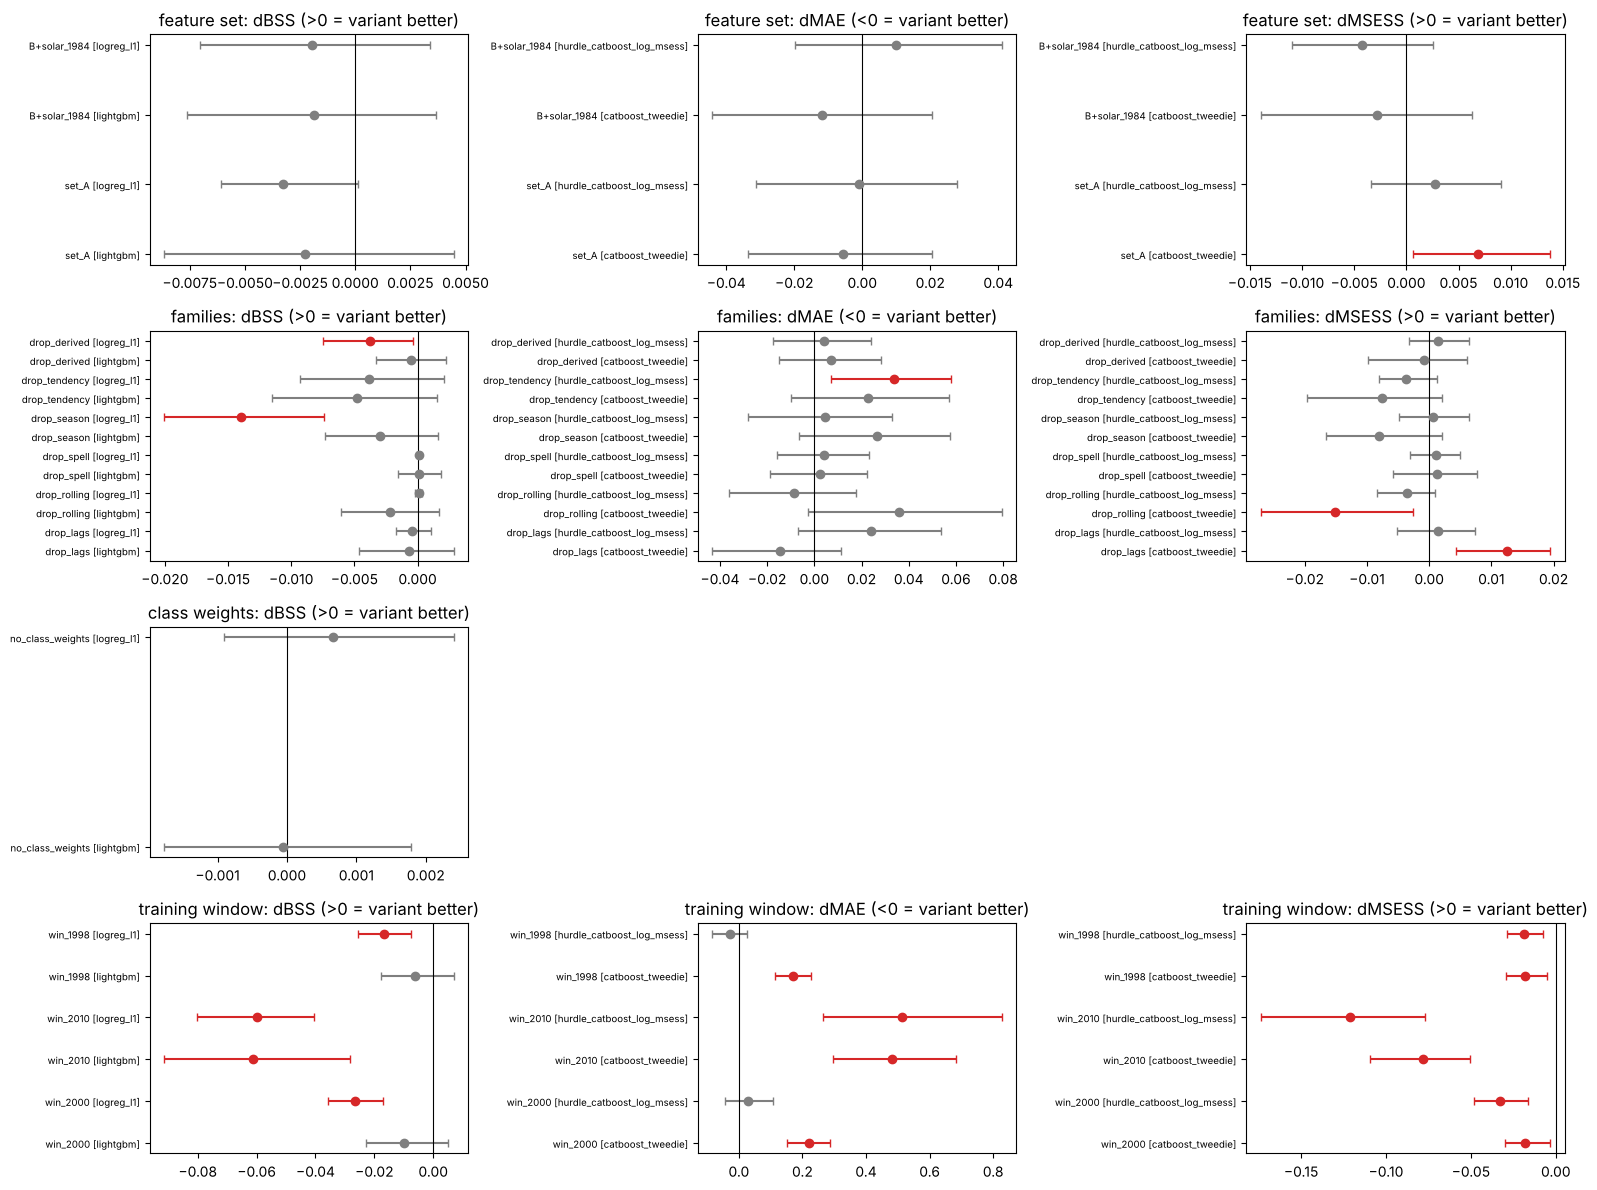

,group,variant,model,versus,metric,folds,n_days,estimate,ci_low,ci_high,significant
0,feature set,set_A,lightgbm,full,dBSS,"1,2,3,4,5",5478,-0.002,-8.700e-03,4.500e-03,False
1,feature set,set_A,logreg_l1,full,dBSS,"1,2,3,4,5",5478,-0.003,-6.100e-03,1.000e-04,False
2,feature set,set_A,catboost_tweedie,full,dMAE,"1,2,3,4,5",5478,-0.006,-3.360e-02,2.060e-02,False
3,feature set,set_A,catboost_tweedie,full,dMSESS,"1,2,3,4,5",5478,0.007,7.000e-04,1.380e-02,True
4,feature set,set_A,hurdle_catboost_log_msess,full,dMAE,"1,2,3,4,5",5478,-0.001,-3.120e-02,2.780e-02,False
...,...,...,...,...,...,...,...,...,...,...,...
63,training window,win_1998,logreg_l1,full,dBSS,"1,2,3,4,5",5478,-0.017,-2.560e-02,-7.400e-03,True
64,training window,win_1998,catboost_tweedie,full,dMAE,"1,2,3,4,5",5478,0.171,1.137e-01,2.264e-01,True
65,training window,win_1998,catboost_tweedie,full,dMSESS,"1,2,3,4,5",5478,-0.018,-2.910e-02,-5.400e-03,True
66,training window,win_1998,hurdle_catboost_log_msess,full,dMAE,"1,2,3,4,5",5478,-0.029,-8.350e-02,2.660e-02,False


In [3]:
GROUPS = {"feature set": [("set_A", "full"), ("B+solar_1984", "B_1984")],
          "families": [(f"drop_{k}", "full") for k in A.FAMILIES],
          "class weights": [("no_class_weights", "full")],
          "training window": [("win_2000", "full"), ("win_2010", "full"), ("win_1998", "full")]}
rows = []
for group, pairs in GROUPS.items():
    for v, base in pairs:
        for task, models in A.MODELS.items():
            if task not in A.VARIANTS[v].get("tasks", ["cls", "reg"]):
                continue
            for m in models:
                rows += [{"group": group, **r} for r in A.delta(v, m, base)]
deltas = pd.DataFrame(rows)
deltas.to_csv(TAB / "06_ablation_deltas.csv", index=False)

panels = [("cls", "dBSS"), ("reg", "dMAE"), ("reg", "dMSESS")]
fig, axes = plt.subplots(len(GROUPS), 3, figsize=(16, 3.0 * len(GROUPS)), squeeze=False)
for i, group in enumerate(GROUPS):
    for j, (task, met) in enumerate(panels):
        ax = axes[i, j]
        d = deltas[(deltas.group == group) & (deltas.metric == met)].reset_index(drop=True)
        if d.empty:
            ax.axis("off"); continue
        for k, r in d.iterrows():
            ax.errorbar(r.estimate, k, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]], fmt="o",
                        color="tab:red" if r.significant else "tab:grey", capsize=3)
        ax.axvline(0, color="k", lw=0.8)
        ax.set(yticks=range(len(d)), yticklabels=[f"{r.variant} [{r.model}]" for _, r in d.iterrows()],
               title=f"{group}: {met}" + (" (>0 = variant better)" if met != "dMAE" else " (<0 = variant better)"))
        ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); save(fig, "06_ablation_forest_classical.png"); plt.show()
deltas.round(4)

**Interpretation (68 differences, 95 % CI):**
- **Feature set:** Set A ≈ Set B (LightGBM ΔBSS −0.002, logreg −0.003, both n.s.). Tweedie is marginally *better* with A (ΔMSESS +0.007).
  Solar radiation adds nothing (all CIs include 0). The four extra NASA variables (PS, QV2M, T2MDEW, WS10M) are redundant with the
  humidity and temperature already in Set A.
- **Families:** no single family is indispensable for LightGBM (all |ΔBSS| ≤ 0.005, n.s.); its information is spread redundantly across
  current values, lags and rolling statistics.
  - `logreg_l1` loses **0.014 BSS without the season family** (CI −0.020 to −0.007). A linear model cannot rebuild the seasonal cycle from
    humidity and temperature, while trees can.
  - `logreg_l1` also loses 0.004 BSS without the derived DPD/DTR.
  - Regression: Tweedie loses MSESS without rolling statistics (−0.015) but *gains* without lags (+0.012); the hurdle loses 0.03 mm MAE without
    tendencies. These are model-specific and small, and with ≈ 70 tests about 3–4 "significant" results are expected by chance.
- **Class weights:** irrelevant (ΔBSS −0.0001 / +0.0007). Classes are nearly balanced (49 % wet), so weighting barely changes the loss.
- **Training window — the one solid result:** shorter histories hurt.
  - `win_2010` (folds 4–5): ΔBSS −0.061 (LightGBM) / −0.060 (logreg), ΔMAE +0.48 / +0.51 mm, ΔMSESS −0.08 / −0.12. All CIs exclude 0.
  - `win_2000`: logreg −0.027 BSS, Tweedie +0.22 mm and −0.018 MSESS; LightGBM −0.010 (n.s.).
  - `win_1998` behaves like `win_2000`.

**Decision:** keep Set B, all feature families, class weights and all training years (1981+). The extra variables and families are not
needed, but removing them buys nothing, and rule 7 favours keeping the pre-specified set. Older, pre-break years help.

**Paper note:** *No single feature family was indispensable for the gradient-boosting model, and the additional NASA POWER variables and
solar radiation gave no measurable benefit; in contrast, restricting training to recent years degraded skill significantly
(e.g. ΔBSS −0.06 and ΔMAE +0.5 mm for training from 2010).*

### Step 5 — Rain-day threshold: are rankings and conclusions robust?

**WHAT:** for 0.1, 1.0 and 2.5 mm: BSS, ROC-AUC, PR-AUC and CSI of LightGBM and `logreg_l1` (5-fold means), BSS of seasonal +
persistence, and the paired difference LightGBM − logreg_l1 (ΔBSS with 95 % CI) — overall and for the post-2014 folds 4–5.

**WHY:** a different threshold is a different target, so "Δ vs full" is meaningless; the question is whether the *ranking* and the
booster advantage survive. **Look for:** the sign of ΔBSS(LightGBM − logreg) at every threshold.

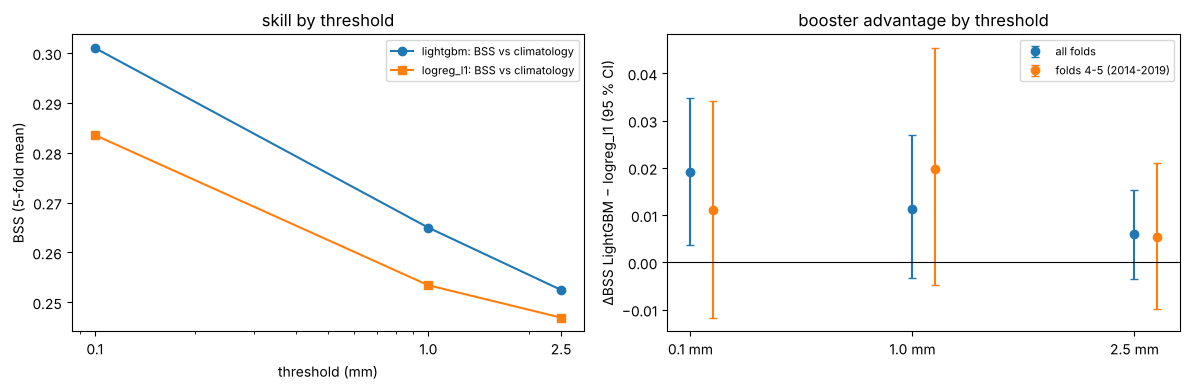

,threshold_mm,model,BSS,BSS_vs_seas_pers,ROC_AUC,PR_AUC,CSI
0,0.1,lightgbm,0.301,0.101,0.963,0.977,0.850
1,0.1,logreg_l1,0.284,0.079,0.961,0.977,0.847
2,1.0,lightgbm,0.265,0.100,0.956,0.953,0.820
3,1.0,logreg_l1,0.253,0.086,0.956,0.955,0.825
4,2.5,lightgbm,0.253,0.111,0.939,0.919,0.767
5,2.5,logreg_l1,0.247,0.105,0.939,0.920,0.764


,threshold_mm,variant,model,versus,metric,folds,n_days,estimate,ci_low,ci_high,significant,subset
0,0.1,thr_0.1,lightgbm,logreg_l1,dBSS,"1,2,3,4,5",5478,0.019,0.004,0.035,True,all
1,0.1,thr_0.1,lightgbm,logreg_l1,dBSS,"4,5",2191,0.011,-0.012,0.034,False,"(4, 5)"
2,1.0,full,lightgbm,logreg_l1,dBSS,"1,2,3,4,5",5478,0.011,-0.003,0.027,False,all
3,1.0,full,lightgbm,logreg_l1,dBSS,"4,5",2191,0.020,-0.005,0.045,False,"(4, 5)"
4,2.5,thr_2.5,lightgbm,logreg_l1,dBSS,"1,2,3,4,5",5478,0.006,-0.004,0.015,False,all
5,2.5,thr_2.5,lightgbm,logreg_l1,dBSS,"4,5",2191,0.005,-0.010,0.021,False,"(4, 5)"


In [4]:
rows = []
for v in ("thr_0.1", "full", "thr_2.5"):
    thr = A.VARIANTS[v].get("thr", 1.0)
    for m in A.MODELS["cls"]:
        r = res[(res.variant == v) & (res.model == m)]
        pf = r.groupby(["metric", "fold"]).value.mean().unstack("fold").mean(axis=1)
        rows.append({"threshold_mm": thr, "model": m, **{k: pf[k] for k in ("BSS", "BSS_vs_seas_pers", "ROC_AUC", "PR_AUC", "CSI")}})
thr_tab = pd.DataFrame(rows)
gap = pd.DataFrame([{"threshold_mm": A.VARIANTS[v].get("thr", 1.0), **r, "subset": "all" if fs is None else str(fs)}
                    for v in ("thr_0.1", "full", "thr_2.5") for fs in (None, (4, 5))
                    for r in A.delta(v, "lightgbm", other_model="logreg_l1", fold_subset=fs)])
thr_tab.to_csv(TAB / "06_ablation_threshold.csv", index=False); gap.to_csv(TAB / "06_ablation_threshold_gap.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, mk in zip(A.MODELS["cls"], "os"):
    t = thr_tab[thr_tab.model == m]
    axes[0].plot(t.threshold_mm, t.BSS, marker=mk, label=f"{m}: BSS vs climatology")
axes[0].set(xscale="log", xticks=[0.1, 1, 2.5], xticklabels=["0.1", "1.0", "2.5"], xlabel="threshold (mm)", ylabel="BSS (5-fold mean)",
            title="skill by threshold"); axes[0].legend(fontsize=8)
for k, (fs, c) in enumerate(((None, "tab:blue"), ((4, 5), "tab:orange"))):
    g = gap[gap.subset == ("all" if fs is None else str(fs))]
    axes[1].errorbar(np.arange(3) + 0.1 * k, g.estimate, yerr=[g.estimate - g.ci_low, g.ci_high - g.estimate], fmt="o", color=c,
                     capsize=3, label="all folds" if fs is None else "folds 4-5 (2014-2019)")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xticks=range(3), xticklabels=["0.1 mm", "1.0 mm", "2.5 mm"], ylabel="ΔBSS LightGBM − logreg_l1 (95 % CI)",
            title="booster advantage by threshold"); axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "06_ablation_threshold.png"); plt.show()
display(thr_tab.round(4)); gap.round(4)

**Interpretation:**
- Skill falls with the threshold for both models: LightGBM BSS 0.301 (0.1 mm) → 0.265 (1.0) → 0.253 (2.5). At 0.1 mm the event is common, so
  persistence of "any rain" carries a lot of information; at 2.5 mm the event depends more on convective intensity.
- **The ranking never changes:** LightGBM beats `logreg_l1` at every threshold, by +0.019 (0.1 mm, CI 0.004–0.035), +0.011 (1.0 mm, CI −0.003 to
  0.027) and +0.006 (2.5 mm, n.s.).
- With a paired monthly block bootstrap, the booster advantage at the primary 1 mm threshold is **not statistically significant**, neither
  overall nor in folds 4–5 (+0.020, CI −0.005 to 0.045). The Stage-4 fold win counts (5/5 folds) were suggestive but are not a significance test.

**Decision:** the conclusions (boosters ≥ linear; both well above seasonal + persistence) are threshold-robust. The size of the booster
advantage over a tuned L1-logistic model is reported as small (≈ 0.01 BSS) and not significant at 1 mm.

**Paper note:** *Model rankings were unchanged at the 0.1, 1.0 and 2.5 mm thresholds, although the advantage of gradient boosting over
L1-regularised logistic regression (0.006–0.019 BSS) was significant only at 0.1 mm.*

### Step 6 — Training window by fold: do the old (pre-break) years help?

**WHAT:** fold-wise (seed-averaged) BSS / MAE of the full model and of the window variants, per model.

**WHY:** the bootstrap in Step 4 pools all validation days; the regime question is about *which* years are being predicted —
folds 4–5 (2014–2019) straddle the 2016 break. **Look for:** whether `win_2000` / `win_2010` win in folds 4–5 and lose in folds 1–3.

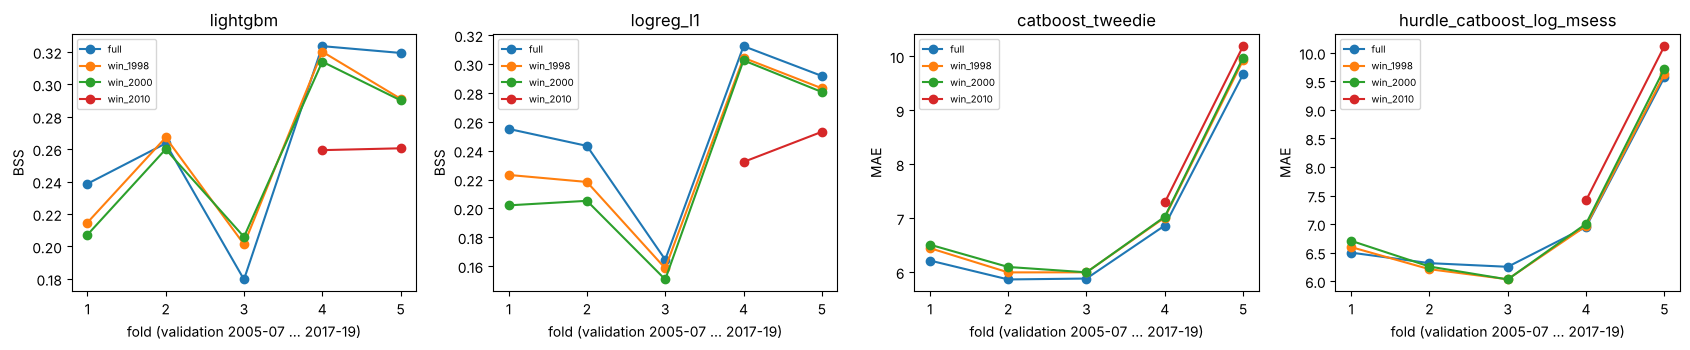

,model,metric,variant,fold 1,fold 2,fold 3,fold 4,fold 5
0,lightgbm,BSS,full,0.239,0.264,0.180,0.324,0.319
1,lightgbm,BSS,win_1998,0.215,0.267,0.201,0.320,0.291
2,lightgbm,BSS,win_2000,0.207,0.260,0.206,0.314,0.290
3,lightgbm,BSS,win_2010,NaN,NaN,NaN,0.259,0.261
4,logreg_l1,BSS,full,0.255,0.243,0.165,0.312,0.292
5,logreg_l1,BSS,win_1998,0.223,0.218,0.159,0.304,0.283
6,logreg_l1,BSS,win_2000,0.202,0.205,0.151,0.303,0.281
7,logreg_l1,BSS,win_2010,NaN,NaN,NaN,0.232,0.253
8,catboost_tweedie,MAE,full,6.214,5.864,5.880,6.863,9.665
9,catboost_tweedie,MAE,win_1998,6.444,5.994,5.996,7.011,9.926


In [5]:
rows = []
for m in A.MODELS["cls"] + A.MODELS["reg"]:
    met = "BSS" if m in A.MODELS["cls"] else "MAE"
    for v in ("full", "win_1998", "win_2000", "win_2010"):
        r = res[(res.variant == v) & (res.model == m) & (res.metric == met)].groupby("fold").value.mean()
        rows.append({"model": m, "metric": met, "variant": v, **{f"fold {k}": r.get(k, np.nan) for k in range(1, 6)}})
win = pd.DataFrame(rows)
win.to_csv(TAB / "06_ablation_window_by_fold.csv", index=False)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, m in zip(axes, A.MODELS["cls"] + A.MODELS["reg"]):
    w = win[win.model == m]
    for _, r in w.iterrows():
        ax.plot(range(1, 6), [r[f"fold {k}"] for k in range(1, 6)], marker="o", label=r.variant)
    ax.set(title=m, xlabel="fold (validation 2005-07 … 2017-19)", ylabel=w.metric.iloc[0], xticks=range(1, 6)); ax.legend(fontsize=7)
fig.tight_layout(); save(fig, "06_ablation_window_by_fold.png"); plt.show()
win.round(4)

**Interpretation:**
- Fold by fold, the window effect is mixed:
  - In **fold 3 (validation 2011–13), `win_2000` is better** for LightGBM (0.206 vs 0.180) — the only fold where dropping the pre-2000
    years (before the first break) helps.
  - In folds 1–2 it is clearly worse (fewer training years: only 5–8).
  - In folds 4–5 it is equal or worse (0.314/0.290 vs 0.324/0.319).
- `win_2010` is worse in both folds 4 and 5, for all four models. Tweedie MAE in fold 5: 10.19 vs 9.67 mm.
- Even right after the 2016 step, a model trained on 4–7 recent years does not beat one trained on 30+ years. On these sample sizes,
  more data matters more than recency.
- **Caveat:** window length and sample size are confounded. A "same number of years, different era" design (e.g. 1981–1995 vs 2000–2014,
  validated on 2015–2019) would separate them.

**Decision:** train on all years. The regime shift is handled by reporting it (Decision 1.1), not by discarding data.

**Paper note:** *Dropping pre-2000 data improved skill only in the 2011–2013 fold, while shorter recent-only training windows were worse
in every post-2014 fold, indicating that sample size outweighed regime consistency at this record length.*

### Step 7 — IMERG as the rain source: do the conclusions hold?

**WHAT:** the same tuned models trained and evaluated with IMERG rainfall (features and targets, 1998–2019) next to their
PRECTOTCORR twin with the same training years (`win_1998`): skill vs climatology and vs seasonal + persistence by fold, and the paired
booster − logistic difference (LightGBM − logreg_l1 ΔBSS; Tweedie − hurdle ΔMAE) for all folds and for folds 4–5.

**WHY:** PRECTOTCORR has step changes (~2000, 2016; Decision 1.9); IMERG is homogeneous. Stage 4 found the boosters' advantage
over logistic regression concentrated after 2016 (Decision 4.9) — if that advantage is a reanalysis artefact, it should vanish with
IMERG. Absolute scores are not comparable across sources (different "truth"); rankings and gaps are.

**Look for:** the sign and size of the booster−logistic gap in folds 4–5 with IMERG.

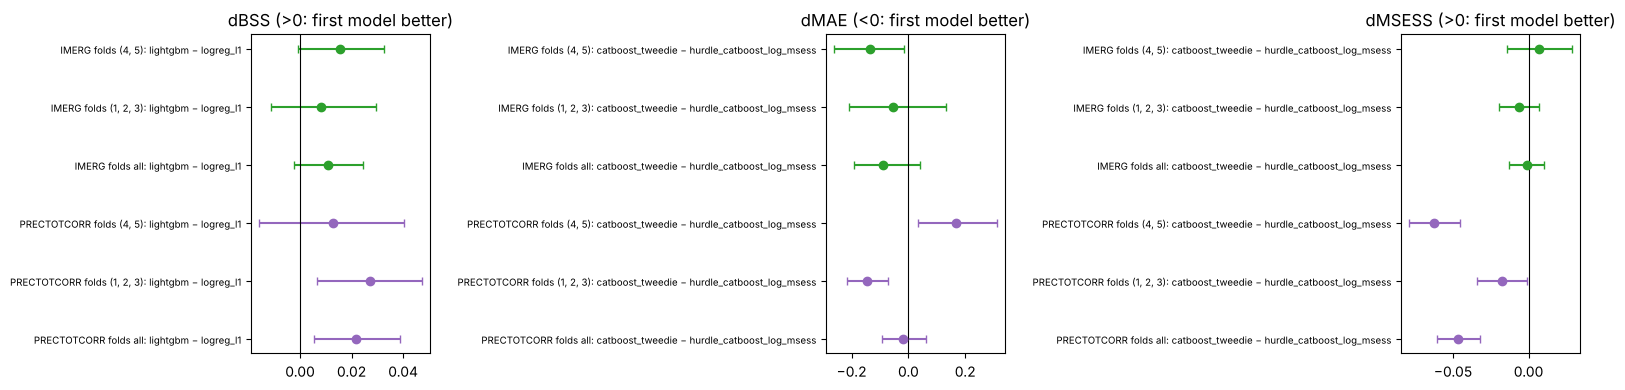

,source,model,metric,fold 1,fold 2,fold 3,fold 4,fold 5,folds 1-3,folds 4-5,all
0,PRECTOTCORR,lightgbm,BSS,0.215,0.267,0.201,0.320,0.291,0.228,0.306,0.259
1,PRECTOTCORR,lightgbm,BSS_vs_seas_pers,0.029,0.094,0.126,0.107,0.101,0.083,0.104,0.092
2,PRECTOTCORR,logreg_l1,BSS,0.223,0.218,0.159,0.304,0.283,0.200,0.294,0.237
3,PRECTOTCORR,logreg_l1,BSS_vs_seas_pers,0.040,0.034,0.079,0.086,0.091,0.051,0.089,0.066
4,PRECTOTCORR,catboost_tweedie,MAE,6.444,5.994,5.996,7.011,9.926,6.145,8.469,7.074
5,PRECTOTCORR,catboost_tweedie,MSESS,0.261,0.160,0.140,0.292,0.334,0.187,0.313,0.237
6,PRECTOTCORR,catboost_tweedie,MSESS_vs_seas_pers,0.049,0.041,0.018,-0.045,-0.019,0.036,-0.032,0.009
7,PRECTOTCORR,hurdle_catboost_log_msess,MAE,6.596,6.209,6.033,6.966,9.621,6.279,8.293,7.085
8,PRECTOTCORR,hurdle_catboost_log_msess,MSESS,0.298,0.161,0.152,0.327,0.408,0.204,0.367,0.269
9,PRECTOTCORR,hurdle_catboost_log_msess,MSESS_vs_seas_pers,0.098,0.042,0.032,0.007,0.094,0.057,0.051,0.054


,source,variant,model,versus,metric,folds,n_days,estimate,ci_low,ci_high,significant,subset
0,PRECTOTCORR,win_1998,lightgbm,logreg_l1,dBSS,"1,2,3,4,5",5478,0.022,5.400e-03,0.039,True,all
1,PRECTOTCORR,win_1998,catboost_tweedie,hurdle_catboost_log_msess,dMAE,"1,2,3,4,5",5478,-0.021,-9.270e-02,0.062,False,all
2,PRECTOTCORR,win_1998,catboost_tweedie,hurdle_catboost_log_msess,dMSESS,"1,2,3,4,5",5478,-0.047,-6.060e-02,-0.032,True,all
3,PRECTOTCORR,win_1998,lightgbm,logreg_l1,dBSS,"1,2,3",3287,0.027,6.700e-03,0.047,True,"(1, 2, 3)"
4,PRECTOTCORR,win_1998,catboost_tweedie,hurdle_catboost_log_msess,dMAE,"1,2,3",3287,-0.146,-2.177e-01,-0.072,True,"(1, 2, 3)"
5,PRECTOTCORR,win_1998,catboost_tweedie,hurdle_catboost_log_msess,dMSESS,"1,2,3",3287,-0.018,-3.400e-02,-0.001,True,"(1, 2, 3)"
6,PRECTOTCORR,win_1998,lightgbm,logreg_l1,dBSS,"4,5",2191,0.013,-1.590e-02,0.040,False,"(4, 5)"
7,PRECTOTCORR,win_1998,catboost_tweedie,hurdle_catboost_log_msess,dMAE,"4,5",2191,0.167,3.250e-02,0.311,True,"(4, 5)"
8,PRECTOTCORR,win_1998,catboost_tweedie,hurdle_catboost_log_msess,dMSESS,"4,5",2191,-0.062,-7.890e-02,-0.045,True,"(4, 5)"
9,IMERG,imerg_1998,lightgbm,logreg_l1,dBSS,"1,2,3,4,5",5478,0.011,-2.300e-03,0.025,False,all


In [6]:
rows = []
for v in ("win_1998", "imerg_1998"):
    for m in A.MODELS["cls"] + A.MODELS["reg"]:
        for met in (("BSS", "BSS_vs_seas_pers") if m in A.MODELS["cls"] else ("MAE", "MSESS", "MSESS_vs_seas_pers")):
            r = res[(res.variant == v) & (res.model == m) & (res.metric == met)].groupby("fold").value.mean()
            rows.append({"source": "IMERG" if "imerg" in v else "PRECTOTCORR", "model": m, "metric": met,
                         **{f"fold {k}": r.get(k) for k in range(1, 6)}, "folds 1-3": r.loc[[1, 2, 3]].mean(),
                         "folds 4-5": r.loc[[4, 5]].mean(), "all": r.mean()})
imerg = pd.DataFrame(rows)
gaps = []
for v in ("win_1998", "imerg_1998"):
    for fs in (None, (1, 2, 3), (4, 5)):
        for r in A.delta(v, "lightgbm", other_model="logreg_l1", fold_subset=fs) + \
                 A.delta(v, "catboost_tweedie", other_model="hurdle_catboost_log_msess", fold_subset=fs):
            gaps.append({"source": "IMERG" if "imerg" in v else "PRECTOTCORR", **r, "subset": "all" if fs is None else str(fs)})
gaps = pd.DataFrame(gaps)
imerg.to_csv(TAB / "06_ablation_imerg.csv", index=False); gaps.to_csv(TAB / "06_ablation_imerg_gaps.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, met in zip(axes, ["dBSS", "dMAE", "dMSESS"]):
    g = gaps[gaps.metric == met].reset_index(drop=True)
    for k, r in g.iterrows():
        ax.errorbar(r.estimate, k, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]], fmt="o", capsize=3,
                    color="tab:green" if r.source == "IMERG" else "tab:purple")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(yticks=range(len(g)), yticklabels=[f"{r.source} folds {r.subset}: {r.model} − {r.versus}" for _, r in g.iterrows()],
           title=met + (" (>0: first model better)" if met != "dMAE" else " (<0: first model better)"))
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); save(fig, "06_ablation_imerg.png"); plt.show()
display(imerg.round(4)); gaps.round(4)

**Interpretation:**
- **Skill is much lower with IMERG.** LightGBM BSS 0.159 vs 0.259 (PRECTOTCORR, same training years); Tweedie MAE 8.31 vs 7.07 mm; MSESS 0.15 vs 0.24.
  Skill over seasonal + persistence is still positive (LightGBM +0.040 BSS, Tweedie +0.024 MSESS).
- **IMERG errors are stable across folds** (Tweedie MAE 8.1–8.5 in every fold). PRECTOTCORR jumps in fold 5 (9.9 mm). This confirms the
  homogeneity of the satellite record and that the fold-5 deterioration of PRECTOTCORR is partly a data artefact.
- **Why much lower skill?** All predictors are MERRA-2 (reanalysis) fields. With PRECTOTCORR the target comes from the same system, so
  tomorrow's reanalysis rain is partly a function of today's reanalysis humidity and circulation (internal model consistency). IMERG is an
  independent observation of rain, so that shared component is gone. Part of the PRECTOTCORR skill is therefore "predicting the reanalysis",
  not predicting observed rain.
- **Conclusions that hold:**
  - The booster − logistic gap keeps its sign with IMERG (+0.011 overall; +0.015 in folds 4–5, CI −0.001 to 0.033, borderline).
  - The gap is *not* concentrated after 2016 in either source. PRECTOTCORR twin: +0.027 in folds 1–3 (significant) vs +0.013 in folds 4–5 (n.s.).
    The Stage-4 impression of a post-2016 booster advantage (Decision 4.9) does not survive a fair paired test.
  - Tweedie vs hurdle keeps its MAE/MSESS trade-off. With IMERG, Tweedie's MAE advantage in folds 4–5 is significant (−0.14 mm) and the
    hurdle's MSESS advantage disappears.

**Decision:** report the IMERG experiment as a robustness check and as the main caveat on absolute skill. The paper's ranking claims
hold for both rain sources; absolute PRECTOTCORR skill should not be read as skill against observed rainfall.

**Paper note:** *Repeating the experiment with IMERG satellite rainfall as both predictor and target preserved the model ranking but
reduced skill markedly (BSS 0.16 vs 0.26), suggesting that part of the apparent skill on PRECTOTCORR reflects the internal consistency
of reanalysis predictors and reanalysis rainfall.*

### Step 8 — Lookback 14 / 30 / 60 (deep models, consolidated from Stage 5)

**WHAT:** the Stage-5 default configurations at L = 30 and 60 minus L = 14 (seed-mean forecasts over the seeds all three lookbacks
share: 3 for TSMixer/TiDE, 1 for TFT), ΔMAE and ΔMSESS with block-bootstrap CIs. No new fits.

**WHY:** Decision 5.8 fixed L = 14 a priori from the PACF and flat curves; this adds the uncertainty the paper needs.
**Look for:** CIs that include 0 (lookback does not matter) vs consistent signs.

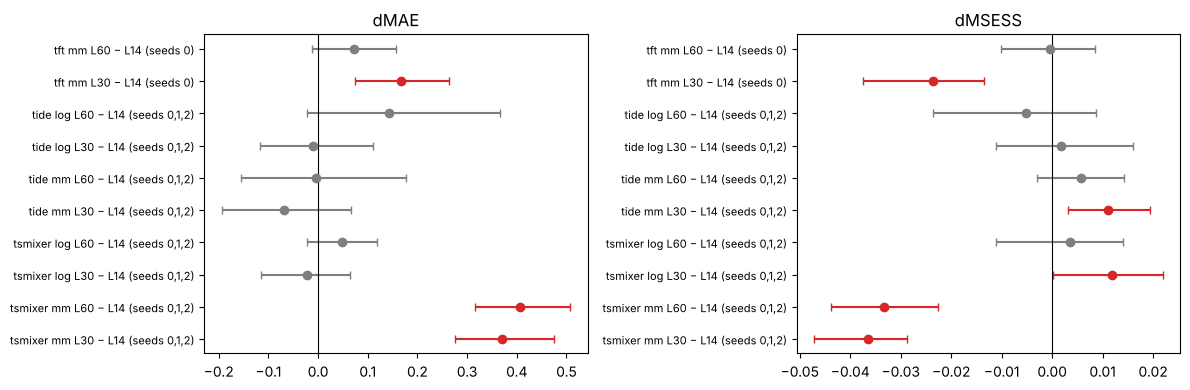

,model,task,variant,versus,seeds,metric,n_days,estimate,ci_low,ci_high,significant
0,tsmixer,reg,tsmixer mm L30,L14,"0,1,2",dMAE,1826,3.701e-01,2.746e-01,0.474,True
1,tsmixer,reg,tsmixer mm L30,L14,"0,1,2",dMSESS,1826,-3.640e-02,-4.710e-02,-0.029,True
2,tsmixer,reg,tsmixer mm L60,L14,"0,1,2",dMAE,1826,4.072e-01,3.157e-01,0.507,True
3,tsmixer,reg,tsmixer mm L60,L14,"0,1,2",dMSESS,1826,-3.320e-02,-4.380e-02,-0.023,True
4,tsmixer,reg,tsmixer log L30,L14,"0,1,2",dMAE,1826,-2.250e-02,-1.158e-01,0.065,False
5,tsmixer,reg,tsmixer log L30,L14,"0,1,2",dMSESS,1826,1.190e-02,2.000e-04,0.022,True
6,tsmixer,reg,tsmixer log L60,L14,"0,1,2",dMAE,1826,4.880e-02,-2.200e-02,0.119,False
7,tsmixer,reg,tsmixer log L60,L14,"0,1,2",dMSESS,1826,3.500e-03,-1.100e-02,0.014,False
8,tide,reg,tide mm L30,L14,"0,1,2",dMAE,1826,-6.930e-02,-1.940e-01,0.067,False
9,tide,reg,tide mm L30,L14,"0,1,2",dMSESS,1826,1.110e-02,3.100e-03,0.019,True


In [7]:
lb = DA.lookback_deltas()
lb.to_csv(TAB / "06_ablation_lookback.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, met in zip(axes, ["dMAE", "dMSESS"]):
    g = lb[lb.metric == met].reset_index(drop=True)
    for k, r in g.iterrows():
        ax.errorbar(r.estimate, k, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]], fmt="o", capsize=3,
                    color="tab:red" if r.significant else "tab:grey")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(yticks=range(len(g)), yticklabels=[f"{r.variant} − L14 (seeds {r.seeds})" for _, r in g.iterrows()], title=met)
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout(); save(fig, "06_ablation_lookback.png"); plt.show()
lb.round(4)

**Interpretation:**
- For the log-target TSMixer and both TiDE routes, L = 30 or 60 is **never significantly better in MAE** than L = 14. Some MSESS gains are
  significant but tiny (+0.011–0.012 for TSMixer-log L30 and TiDE-mm L30).
- Some longer lookbacks are clearly worse: TSMixer-mm L30/L60 (+0.37/+0.41 mm MAE) and TFT L30 (+0.17 mm; 1 seed).
- No lookback beats L = 14 robustly. The a-priori choice (Decision 5.8) is supported: rain memory beyond two weeks is not exploited by
  these networks.

**Decision:** keep L = 14 for all deep models.

**Paper note:** *Extending the lookback window from 14 to 30 or 60 days never reduced MAE significantly and increased it for TSMixer
(direct target) and TFT.*

### Step 9 — Deep-model ablations (DL split)

**WHAT:** the tuned deep model of each task (see `06_tuning_part2.ipynb`) refitted on `set_A_vars`, `win_2000`, `imerg_1998` and, for
classification, `thr_0.1` / `thr_2.5`; 3 seeds (0–2) each, compared with the tuned full configuration's seeds 0–2. Δ vs full only where
the target is unchanged (variables, window); for IMERG and thresholds we report levels and the gap to the tuned classical model refitted
on the same target is out of scope (noted).

**WHY:** checks whether the deep model's skill depends on the same ingredients as the classical models'. 3 seeds per variant
(compute; Decision 5.4 precedent) — stated as a limitation.

**Look for:** whether the extra variables or the old years matter for the network.

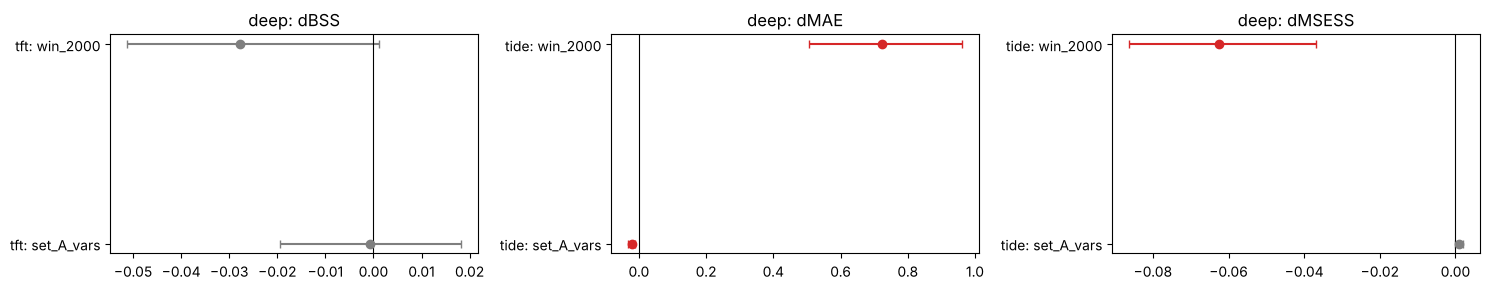

metric                   BSS  ROC_AUC  PR_AUC     MAE  MSESS   bias
task model variant                                                 
cls  tft   full        0.311    0.965   0.972     NaN    NaN    NaN
           imerg_1998  0.132    0.931   0.922     NaN    NaN    NaN
           set_A_vars  0.301    0.965   0.971     NaN    NaN    NaN
           thr_0.1     0.334    0.972   0.985     NaN    NaN    NaN
           thr_2.5     0.294    0.951   0.953     NaN    NaN    NaN
           win_2000    0.284    0.964   0.971     NaN    NaN    NaN
reg  tide  full          NaN      NaN     NaN   9.469  0.398 -0.612
           imerg_1998    NaN      NaN     NaN   9.495  0.052 -0.085
           set_A_vars    NaN      NaN     NaN   9.448  0.399 -0.662
           win_2000      NaN      NaN     NaN  10.321  0.315 -0.527

,model,task,variant,versus,metric,n_days,estimate,ci_low,ci_high,significant
0,tft,cls,set_A_vars,full,dBSS,1826,-7.000e-04,-1.940e-02,0.018,False
1,tft,cls,win_2000,full,dBSS,1826,-2.780e-02,-5.130e-02,0.001,False
2,tide,reg,set_A_vars,full,dMAE,1826,-2.150e-02,-3.270e-02,-0.011,True
3,tide,reg,set_A_vars,full,dMSESS,1826,9.000e-04,-1.000e-04,0.002,False
4,tide,reg,win_2000,full,dMAE,1826,7.242e-01,5.048e-01,0.962,True
5,tide,reg,win_2000,full,dMSESS,1826,-6.250e-02,-8.630e-02,-0.037,True


In [8]:
KINDS = {"cls": "tft", "reg": "tide"}       # best deep model per task (06_tuning_part2.ipynb, Steps 7-9)
dres = DA.run_all(KINDS, workers=4)
lvl = dres.pivot_table(index=["task", "model", "variant"], columns="metric", values="value", aggfunc="mean")
lvl = lvl[[c for c in ("BSS", "ROC_AUC", "PR_AUC", "MAE", "MSESS", "bias") if c in lvl]]
drows = []
for task, kind in KINDS.items():
    for v in ("set_A_vars", "win_2000"):
        drows += DA.delta(kind, task, v)
ddeep = pd.DataFrame(drows)
ddeep.to_csv(TAB / "06_ablation_deep_deltas.csv", index=False); lvl.to_csv(TAB / "06_ablation_deep_levels.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, met in zip(axes, ["dBSS", "dMAE", "dMSESS"]):
    g = ddeep[ddeep.metric == met].reset_index(drop=True)
    for k, r in g.iterrows():
        ax.errorbar(r.estimate, k, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]], fmt="o", capsize=3,
                    color="tab:red" if r.significant else "tab:grey")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(yticks=range(len(g)), yticklabels=[f"{r.model}: {r.variant}" for _, r in g.iterrows()], title=f"deep: {met}")
fig.tight_layout(); save(fig, "06_ablation_deep.png"); plt.show()
display(lvl.round(4)); ddeep.round(4)

**Interpretation (3 seeds per variant):**
- **TFT classification** (full 0.311 on seeds 0–2):
  - Set-A variables only: −0.001 (n.s.).
  - Training from 2000: −0.028 (CI −0.051 to 0.001, borderline). Again, older years help.
  - IMERG: BSS 0.132 (vs LightGBM-IMERG 0.159 on the CV folds — different splits, indicative only).
  - Thresholds: 0.334 (0.1 mm) / 0.294 (2.5 mm), the same pattern as the classical models.
- **TiDE regression** (log + smearing):
  - Set-A variables: **slightly better** MAE (−0.022 mm, significant), MSESS unchanged.
  - Training from 2000: much worse (+0.72 mm MAE, −0.063 MSESS).
  - IMERG: MSESS collapses to 0.05 (MAE 9.50). The network's MSE skill depends heavily on PRECTOTCORR's reanalysis consistency.
- The three monsoon-AUC flags (thr_0.1) are the small-sample effect explained in Step 11.

**Decision:** the deep ablations support the classical ones: extra variables do not help, and older years do. No change to the deep configurations.

**Paper note:** *The deep models responded to the ablations like the classical ones: removing the additional NASA variables did not reduce
skill, whereas shortening the training record did.*

### Step 10 — Master ablation table

**WHAT:** every Δ with its CI in one table (`reports/tables/06_ablation_master.csv`), with a verdict: **solid** (CI excludes 0 for
all models of the task in the same direction), **model-specific** (CI excludes 0 for one model only), **noise** (CIs include 0).

**WHY:** one place for the paper's ablation table; the verdict rule is fixed before reading it, so it cannot be bent to the result.

In [9]:
master = pd.concat([deltas.assign(suite="classical CV"),
                    gaps.assign(group="rain source / model gap", suite="classical CV", variant=gaps.source + " folds " + gaps.subset),
                    gap.assign(group="threshold / model gap", suite="classical CV",
                               variant="thr " + gap.threshold_mm.astype(str) + " folds " + gap.subset),
                    lb.assign(group="lookback", suite="deep DL split"),
                    ddeep.assign(group="deep variables / window", suite="deep DL split")], ignore_index=True)
master = master[["suite", "group", "variant", "model", "versus", "metric", "estimate", "ci_low", "ci_high", "significant"]]
def verdict(g):
    sig = g[g.significant]
    if len(sig) == 0:
        return "noise"
    same = (np.sign(sig.estimate).nunique() == 1) and len(sig) == len(g)
    return "solid" if same else "model-specific"
v = master.groupby(["suite", "group", "variant", "versus", "metric"]).apply(verdict, include_groups=False).rename("verdict")
master = master.merge(v.reset_index(), on=["suite", "group", "variant", "versus", "metric"])
master.to_csv(TAB / "06_ablation_master.csv", index=False)
with pd.option_context("display.max_rows", 200):
    display(master.round(4))
print(master.drop_duplicates(["suite", "group", "variant", "versus", "metric"]).verdict.value_counts())

,suite,group,variant,model,versus,metric,estimate,ci_low,ci_high,significant,verdict
0,classical CV,feature set,set_A,lightgbm,full,dBSS,-2.300e-03,-8.700e-03,4.500e-03,False,noise
1,classical CV,feature set,set_A,logreg_l1,full,dBSS,-3.300e-03,-6.100e-03,1.000e-04,False,noise
2,classical CV,feature set,set_A,catboost_tweedie,full,dMAE,-5.800e-03,-3.360e-02,2.060e-02,False,noise
3,classical CV,feature set,set_A,catboost_tweedie,full,dMSESS,6.900e-03,7.000e-04,1.380e-02,True,model-specific
4,classical CV,feature set,set_A,hurdle_catboost_log_msess,full,dMAE,-1.100e-03,-3.120e-02,2.780e-02,False,noise
5,classical CV,feature set,set_A,hurdle_catboost_log_msess,full,dMSESS,2.700e-03,-3.400e-03,9.100e-03,False,model-specific
6,classical CV,feature set,B+solar_1984,lightgbm,B_1984,dBSS,-1.900e-03,-7.600e-03,3.700e-03,False,noise
7,classical CV,feature set,B+solar_1984,logreg_l1,B_1984,dBSS,-2.000e-03,-7.000e-03,3.400e-03,False,noise
8,classical CV,feature set,B+solar_1984,catboost_tweedie,B_1984,dMAE,-1.200e-02,-4.410e-02,2.050e-02,False,noise
9,classical CV,feature set,B+solar_1984,catboost_tweedie,B_1984,dMSESS,-2.800e-03,-1.400e-02,6.300e-03,False,noise


verdict
noise             49
solid             25
model-specific    10
Name: count, dtype: int64


**Interpretation:** of 84 variant × metric groups, **49 are noise**, 10 are model-specific (one model significant) and 25 are "solid".
The solid ones fall into four themes:
1. **Shorter training windows hurt** (`win_2010` in all metrics; `win_2000` / `win_1998` in MSESS), for the classical and the deep model.
2. **Model comparisons:** LightGBM > logreg_l1 with PRECTOTCORR (1998+ training, overall and in folds 1–3) and at 0.1 mm; hurdle > Tweedie on
   MSESS and Tweedie > hurdle on MAE (the known MAE/MSESS trade-off).
3. **Lookback:** longer windows are worse for TSMixer-mm and TFT; small MSESS gains for TSMixer-log / TiDE-mm at L30.
4. **Deep:** Set-A variables slightly better for TiDE MAE; win_2000 worse.

The verdict rule ignores multiplicity. About 4 of 84 groups would look significant by chance, which matters most for the isolated
model-specific family effects (drop_lags, drop_rolling, drop_tendency, drop_derived, set_A for Tweedie).

**Decision:** in the paper, claim only the window effect, the threshold/source robustness of the ranking, and the redundancy of feature
families and extra variables. Model-specific family effects are listed in the supplement as exploratory.

**Paper note:** *Of 84 ablation contrasts, 49 were indistinguishable from resampling noise; the robust effects were the loss of skill with
shorter training records and the stability of model rankings across thresholds and rainfall sources.*

### Step 11 — Red flags after Stage 6 (rule 11) and test-set audit

**WHAT:** (a) plausibility triggers on every ablation and deep-tuning result (BSS > 0.45, monsoon ROC-AUC > 0.90, MSESS > 0.60 in any
fold / on the validation period); (b) latest target date in every stored forecast file of Stage 6 (classical OOF, ablation OOF, deep
tuned and deep ablation forecasts); (c) which files unlock the test getter.

**Look for:** zero hits; 2019-12-31; only `tests/test_splits.py`.

In [10]:
abl = pd.read_csv(A.RESULTS); dt = pd.read_csv(DT.RESULTS)
checks = [("ablation CV", abl), ("deep tuned", dt.rename(columns={"config": "variant"})), ("deep ablation", dres)]
for name, t in checks:
    hits = pd.concat([t[(t.metric == "BSS") & (t.value > 0.45)], t[(t.metric == "ROC_AUC_monsoon") & (t.value > 0.90)],
                      t[(t.metric == "MSESS") & (t.value > 0.60)]])
    print(f"{name:14s} rows {len(t):6d} | rule-11 hits {len(hits)} | max BSS {t[t.metric == 'BSS'].value.max():.3f} | "
          f"max monsoon ROC-AUC {t[t.metric == 'ROC_AUC_monsoon'].value.max():.3f} | max MSESS {t[t.metric == 'MSESS'].value.max():.3f}")
    if len(hits):
        print("   hits by variant/metric:", hits.groupby(["variant", "metric"]).size().to_dict())
X = E.load("B")[0].join(E.load("B")[1])
for k, (tr, va) in enumerate(S.cv_folds(X.index), 1):
    mon = va[S.target_dates(va).month.isin(E.MONSOON)]
    print(f"fold {k}: dry monsoon days at 0.1 mm = {int((X.loc[mon, 'y_cls_01'] == 0).sum())}, at 1 mm = {int((X.loc[mon, 'y_cls'] == 0).sum())}")
files = list(A.OUT.glob("*.parquet")) + list(DT.TUNED_DIR.glob("*.parquet")) + list(DA.OUT.glob("*.parquet"))
last = max(pd.read_parquet(f).index.max() for f in files) + pd.Timedelta(days=1)
print(f"Stage-6 forecast files checked: {len(files)} | latest target date: {last.date()}")
Rep.test_set_audit()

ablation CV    rows  21544 | rule-11 hits 13 | max BSS 0.338 | max monsoon ROC-AUC 0.972 | max MSESS 0.451
   hits by variant/metric: {('thr_0.1', 'ROC_AUC_monsoon'): 13}
deep tuned     rows   1260 | rule-11 hits 0 | max BSS 0.327 | max monsoon ROC-AUC 0.847 | max MSESS 0.400
deep ablation  rows    558 | rule-11 hits 3 | max BSS 0.343 | max monsoon ROC-AUC 0.958 | max MSESS 0.400
   hits by variant/metric: {('thr_0.1', 'ROC_AUC_monsoon'): 3}
fold 1: dry monsoon days at 0.1 mm = 16, at 1 mm = 44
fold 2: dry monsoon days at 0.1 mm = 14, at 1 mm = 28
fold 3: dry monsoon days at 0.1 mm = 14, at 1 mm = 38
fold 4: dry monsoon days at 0.1 mm = 12, at 1 mm = 28
fold 5: dry monsoon days at 0.1 mm = 0, at 1 mm = 6


Stage-6 forecast files checked: 350 | latest target date: 2019-12-31


{'OOF files checked': 425,
 'latest target date in any OOF file': '2019-12-31',
 'folds present in cv_results': [1, 2, 3, 4, 5],
 'files calling test_index(..., confirm_final=True)': ['tests/test_splits.py']}

**Interpretation:**
- **(a) 16 rule-11 hits, all of them monsoon ROC-AUC for the 0.1 mm target** (13 classical: folds 1, 3, 4; 3 deep), up to 0.972. I
  investigated them before reporting (rule 11):
  - At 0.1 mm, 96 % of monsoon days are wet, so each validation fold has only **12–16 dry monsoon days** (0 in fold 5, where the AUC is
    undefined).
  - An AUC from a dozen negatives is very noisy, and the few rain-free monsoon days are extreme monsoon breaks that are easy to recognise.
  - It is not leakage: the features, folds and code are identical to the 1 mm runs (whose monsoon AUC is 0.77–0.85), and the leakage tests cover
    this code path. The same code at 2.5 mm gives 0.74–0.81.
  - The trigger (Decision 3.8) was calibrated for the 1 mm target.
- **(b) Test-set audit:** 350 Stage-6 forecast files and 425 OOF files all end at target date 2019-12-31. Only `tests/test_splits.py`
  unlocks the test getter.

**Decision:** no red flags. The 0.1 mm monsoon AUC is reported with its sample size, and the rule-11 monsoon trigger is stated as
applying to the 1 mm target.

**Paper note:** *Monsoon-season discrimination at the 0.1 mm threshold (ROC-AUC up to 0.97) rests on only 12–16 rain-free days per
three-year fold and is reported as unstable rather than as evidence of skill.*

### SKEPTICAL-REVIEWER — what a critical reviewer would attack, and our answer

| # | Criticism | Answer / status |
|---|---|---|
| 1 | *"Your CV scores of tuned models are optimistic — you selected on the same folds."* | Yes. Seed-specific optimism was quantified (≈ 0.003 BSS for boosters) and removed with seeds 1–4. Fold-selection optimism remains; only the locked 2020–2025 test set removes it. The deep models were selected on the 2012–2014 slice, so their 2015–2019 scores carry no selection optimism. |
| 2 | *"Ablations used the full model's hyper-parameters — variants were not re-tuned, so 'full' is favoured."* | True by design (one change at a time). Any harm from removing a family is an upper bound, any harm from restricting the window may be overstated. Since almost all family/variable effects are ≈ 0 even with this bias, the redundancy conclusion is conservative. |
| 3 | *"With ≈ 84 tests some 'significant' effects are chance."* | Agreed: ≈ 4 false positives are expected. We claim only effects that are consistent across models and metrics (window) or are rankings (threshold, source). Model-specific family effects are exploratory. CIs also exclude seed variance (seed-mean forecasts). |
| 4 | *"The window effect is just sample size."* | Possibly — length and era are confounded. We say "more data outweighed recency at this record length" and propose an equal-length design. |
| 5 | *"Your skill is reanalysis predicting itself."* | Partly, yes (IMERG BSS 0.16 vs 0.26). This is now an explicit limitation; rankings hold with IMERG. |
| 6 | *"The booster advantage after 2016 was a Stage-4 claim."* | Withdrawn in its strong form. With a paired monthly bootstrap the 1 mm advantage is ≈ +0.01 BSS and not significant, and it is not concentrated after 2016 (DECISIONS 6.12). |
| 7 | *"CatBoost was your finalist, but ablations used LightGBM; the hurdle used LightGBM probabilities."* | Compute (≈ 12 h vs 1 h). LightGBM ties CatBoost (0.265). The ablation hurdle is a documented variant, not the headline model. |
| 8 | *"Deep tuning failed because you tuned on the wrong period."* | The slice is the only honest period available without spending the validation set. The failure itself is the finding: regime change between 2012–14 and 2015–19 makes selection unreliable. |
| 9 | *"Deep ablations used 3 seeds; TFT lookback used 1 seed."* | Stated limitations (compute). TFT seed std ≈ 0.016–0.018 BSS, so only effects > 0.03 are interpretable — consistent with how we report them. |
| 10 | *"0.1 mm monsoon AUC of 0.97 smells of leakage."* | Investigated: 12–16 negatives per fold, identical pipeline, leakage tests pass (Step 11). |

**Bugs found and fixed in Stage 6, part 2 (rule 12):**
- **Notebook key collision:** `ablation.delta` returns a `folds` field that overwrote my fold-subset label. This was caught by a failing
  plot (array sizes differed) before any number was reported; the label was renamed `subset`.
- **`models.linear_pre` hard-coded `month`,** so `drop_season` would have crashed the logistic pipeline. The selector is now conditional;
  results with `month` are identical.
- **CPU oversubscription with 4 torch threads** made a 50-s run take 724 s. All deep runs now use one thread; the refactored code reproduces
  Stage 5 exactly (max diff 0.0 mm).

### Stage 6 part 2b — summary (ablations)

1. Feature Set A ≈ B, solar radiation adds nothing, no single feature family is indispensable for LightGBM; `logreg_l1` needs the season terms.
2. Class weights do not matter (classes nearly balanced).
3. **Shorter training windows hurt**, even after the 2016 break (`win_2010`: −0.06 BSS, +0.5 mm MAE). Use all years.
4. Rankings are robust to the threshold (0.1/1.0/2.5 mm) and to the rain source (IMERG). The booster advantage over tuned L1-logistic is small
   (≈ 0.01 BSS), significant only at 0.1 mm, and not concentrated after 2016.
5. IMERG skill is much lower (BSS 0.16 vs 0.26): part of the PRECTOTCORR skill is reanalysis self-consistency.
6. Lookback 14 is never beaten significantly; deep ablations agree with the classical ones.

---

## END-OF-STAGE 6 — five things you must be able to explain in the paper

1. **How hyper-parameters were chosen without touching the test set,** and which optimism remains: classical models were tuned on the CV
   validation folds (fold-selection optimism; seed optimism removed with seeds 1–4), deep models on the 2012–2014 slice (no optimism in their
   2015–2019 scores). Optuna TPE + median pruning, budgets stated, leakage tests.
2. **What tuning bought:** small, consistent gains for the boosters (+0.004–0.006 BSS, 5/5 folds); a repaired SGD (+0.064); regression MAE
   −0.03 to −0.11 mm at the price of more negative bias; nothing for the deep models (TiDE-cls aside), whose slice gains did not transfer to
   2015–2019.
3. **The cost-vs-skill verdict:** tuned LightGBM (BSS 0.329, 9 s per fit) beats the best deep model (TFT 0.305, 230–650 s) on identical days, and
   nothing beats seasonal + persistence on 2015–2019 MAE. Deep models are justified only for quantiles (TFT) and MSE skill (TiDE).
4. **What carries the skill:** redundant information across families — essentially "today's state + season", with older years helping more
   than recency. Extra NASA variables, solar radiation and class weights are unnecessary.
5. **How far the conclusions generalise:** rankings hold across thresholds and with IMERG, but absolute skill is inflated by reanalysis
   self-consistency (IMERG BSS 0.16 vs 0.26), and the booster advantage over a tuned linear model is small and not significant at 1 mm.

## Check your understanding (3 questions)
1. Tuning the deep models on the 2012–2014 slice improved their slice scores but not their 2015–2019 scores. Why can this happen here, and why
   is tuning on the slice still more defensible than tuning directly on 2015–2019?
2. Training only on 2010+ data was worse even in folds 4–5, which straddle the 2016 break. Give two explanations (one about sample size,
   one about the regime), and describe an ablation that would separate them without touching the test set.
3. With IMERG, BSS falls from ≈ 0.26 to ≈ 0.16 while the model ranking is preserved. What does this tell you about where part of the
   PRECTOTCORR skill comes from, and how should the paper phrase its headline skill numbers because of it?